In [1]:
from pathlib import Path
from datetime import date
import json
import numpy as np
import pandas as pd
import zarr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/processed/manifest.json").exists() and ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
DAY = date(2025, 1, 15)
YEAR = str(DAY.year)
DAY_INDEX = DAY.timetuple().tm_yday - 1

manifest = json.loads((DATA / "manifest.json").read_text())
aod_group = zarr.open_group(str(DATA / "aod.zarr" / YEAR), mode="r")
era_group = zarr.open_group(str(DATA / "era5.zarr" / YEAR), mode="r")
merra_group = zarr.open_group(str(DATA / "merra2.zarr" / YEAR), mode="r")
static = zarr.open_group(str(DATA / "static.zarr"), mode="r")

aod_raw = aod_group["aod"][DAY_INDEX]
accepted_count = aod_group["accepted_count"][DAY_INDEX]
target_mask = static["target_mask"][:].astype(bool)
context_mask = static["context_mask"][:].astype(bool)
aod_valid = (aod_raw != -32768) & context_mask
aod = np.where(aod_valid, aod_raw.astype("float32") * 0.001, np.nan)
era = era_group["era5"][DAY_INDEX]
merra = merra_group["totexttau"][DAY_INDEX]

assert manifest["completed_dates"]["aod"] == [DAY.strftime("%Y%m%d")]
assert manifest["completed_dates"]["era5"] == [DAY.strftime("%Y%m%d")]
assert manifest["completed_dates"]["merra2"] == [DAY.strftime("%Y%m%d")]
assert int(aod_group["complete"][DAY_INDEX].sum()) == 11
print(f"Loaded {DAY.isoformat()} | AOD grid {aod.shape} | ERA5 grid {era.shape} | MERRA-2 grid {merra.shape}")
print(f"Pilot years in stores: {manifest['years']} | Zarr v2 | DEM present: {'elevation_m' in static}")

Loaded 2025-01-15 | AOD grid (3116, 3082) | ERA5 grid (6, 341, 321) | MERRA-2 grid (68, 52)
Pilot years in stores: [2025] | Zarr v2 | DEM present: False


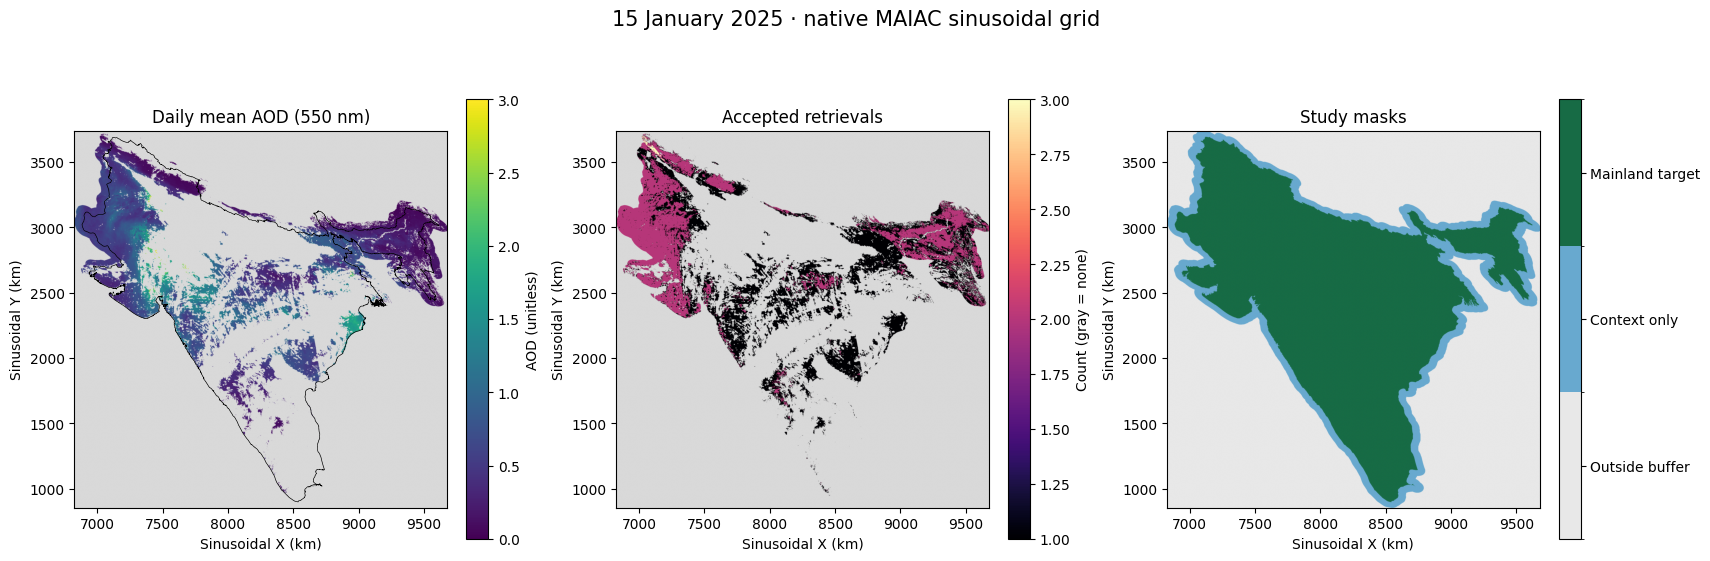

In [2]:
grid = manifest["target_grid"]
transform = grid["crs_transform"]
resolution_km = grid["resolution_m"] / 1000
height, width = target_mask.shape
x0, y0 = transform[2] / 1000, transform[5] / 1000
extent = [x0, x0 + width * resolution_km,
          y0 - height * resolution_km, y0]
x_centres = x0 + (np.arange(width) + .5) * resolution_km
y_centres = y0 - (np.arange(height) + .5) * resolution_km

mask_classes = np.zeros(target_mask.shape, dtype="uint8")
mask_classes[context_mask] = 1
mask_classes[target_mask] = 2
fig, axes = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
for ax in axes:
    ax.set_xlabel("Sinusoidal X (km)")
    ax.set_ylabel("Sinusoidal Y (km)")
    ax.set_aspect("equal")

aod_cmap = plt.colormaps["viridis"].copy()
aod_cmap.set_bad("#d9d9d9")
im = axes[0].imshow(np.ma.masked_invalid(aod), extent=extent, origin="upper",
                    cmap=aod_cmap, vmin=0, vmax=3)
axes[0].contour(x_centres, y_centres, target_mask.astype(float), levels=[.5],
                colors="black", linewidths=.45)
axes[0].set_title("Daily mean AOD (550 nm)")
fig.colorbar(im, ax=axes[0], label="AOD (unitless)", shrink=.78)

count_cmap = plt.colormaps["magma"].copy()
count_cmap.set_bad("#d9d9d9")
count_view = np.ma.masked_where((~context_mask) | (accepted_count == 0), accepted_count)
im = axes[1].imshow(count_view, extent=extent, origin="upper", cmap=count_cmap,
                    vmin=1, vmax=max(1, int(np.max(accepted_count))))
axes[1].set_title("Accepted retrievals")
fig.colorbar(im, ax=axes[1], label="Count (gray = none)", shrink=.78)

mask_cmap = ListedColormap(["#e8e8e8", "#68a9cf", "#176b45"])
im = axes[2].imshow(mask_classes, extent=extent, origin="upper", cmap=mask_cmap,
                    norm=BoundaryNorm([-.5, .5, 1.5, 2.5], mask_cmap.N))
axes[2].set_title("Study masks")
cbar = fig.colorbar(im, ax=axes[2], ticks=[0, 1, 2], shrink=.78)
cbar.ax.set_yticklabels(["Outside buffer", "Context only", "Mainland target"])
fig.suptitle("15 January 2025 · native MAIAC sinusoidal grid", fontsize=15)
plt.show()

,Region,Pixels,Pixels with AOD,Coverage
0,Mainland target,3470049,1228442,35.4%
1,50 km context buffer,4241000,1519735,35.8%


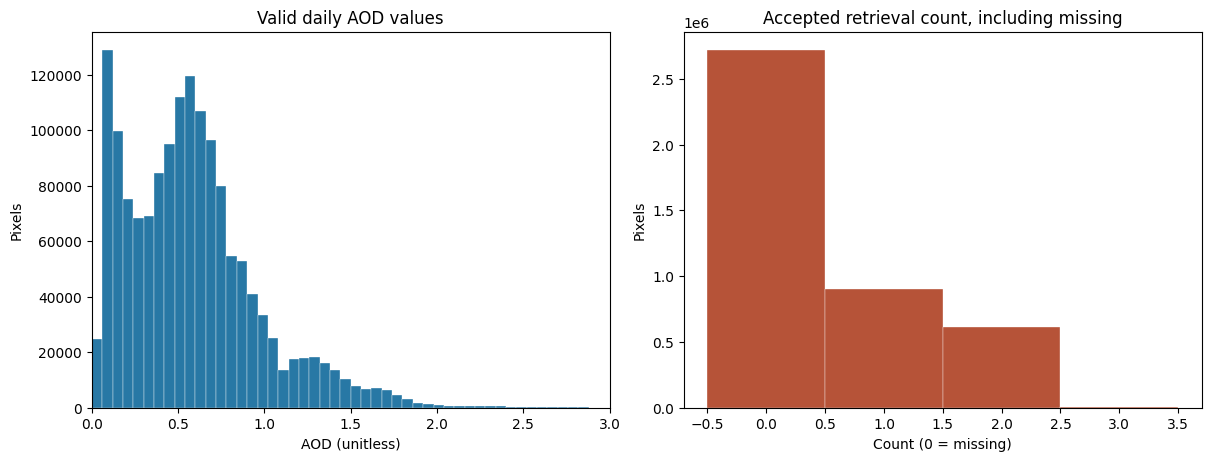

Valid AOD range: 0.000–2.999; stored precision: 0.001
AOD chunks complete: 11/11


In [3]:
target_valid = aod_valid & target_mask
context_valid_count = int(aod_valid.sum())
target_valid_count = int(target_valid.sum())
coverage = pd.DataFrame([
    {"Region": "Mainland target", "Pixels": int(target_mask.sum()),
     "Pixels with AOD": target_valid_count,
     "Coverage": target_valid_count / int(target_mask.sum())},
    {"Region": "50 km context buffer", "Pixels": int(context_mask.sum()),
     "Pixels with AOD": context_valid_count,
     "Coverage": context_valid_count / int(context_mask.sum())},
])
display(coverage.style.format({"Coverage": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].hist(aod[aod_valid], bins=50, color="#2878a5", edgecolor="white", linewidth=.25)
axes[0].set(title="Valid daily AOD values", xlabel="AOD (unitless)", ylabel="Pixels")
axes[0].set_xlim(0, 3)
axes[1].hist(accepted_count[context_mask], bins=np.arange(-.5, max(accepted_count.max(), 1) + 1.5),
             color="#b65338", edgecolor="white", linewidth=.25)
axes[1].set(title="Accepted retrieval count, including missing", xlabel="Count (0 = missing)", ylabel="Pixels")
plt.show()

print(f"Valid AOD range: {np.nanmin(aod):.3f}–{np.nanmax(aod):.3f}; stored precision: 0.001")
print(f"AOD chunks complete: {int(aod_group['complete'][DAY_INDEX].sum())}/11")

## ERA5-Land weather


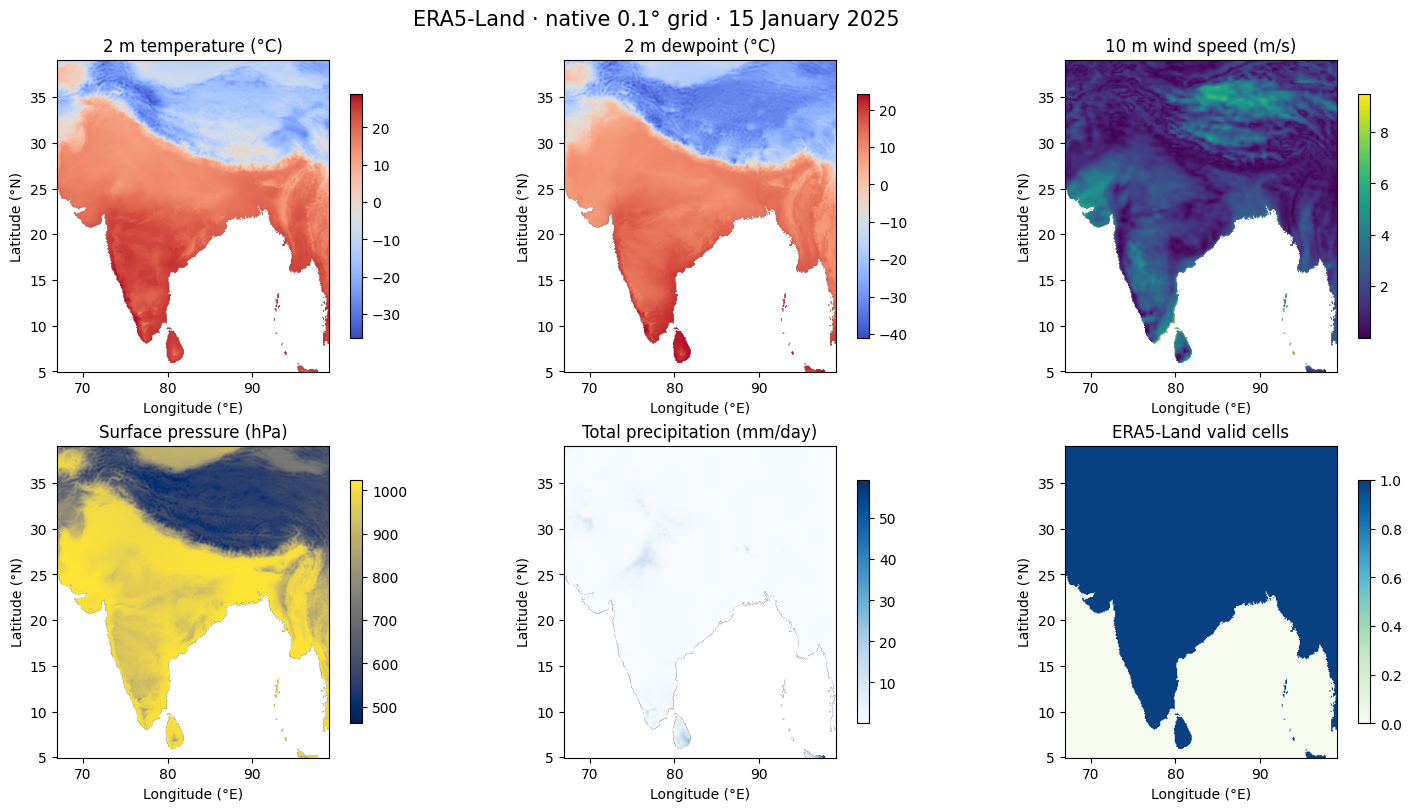

QC counts: {'nonfinite_values': 0, 'fill_values': 239706, 'precip_below_zero': 0, 'precip_above_1m': 0}
Bands: ['temperature_2m', 'dewpoint_temperature_2m', 'u_component_of_wind_10m', 'v_component_of_wind_10m', 'surface_pressure', 'total_precipitation_sum']
Land cells valid in this bounding box: 69,510/109,461


In [4]:
bands = [b.decode() if isinstance(b, bytes) else str(b) for b in era_group["band"][:]]
fill = -9999
valid = era != fill
wind_valid = valid[2] & valid[3]
weather = [
    ("2 m temperature (°C)", np.where(valid[0], era[0] - 273.15, np.nan), "coolwarm"),
    ("2 m dewpoint (°C)", np.where(valid[1], era[1] - 273.15, np.nan), "coolwarm"),
    ("10 m wind speed (m/s)", np.where(wind_valid, np.hypot(era[2], era[3]), np.nan), "viridis"),
    ("Surface pressure (hPa)", np.where(valid[4], era[4] / 100, np.nan), "cividis"),
    ("Total precipitation (mm/day)", np.where(valid[5], era[5] * 1000, np.nan), "Blues"),
    ("ERA5-Land valid cells", valid[0].astype(float), "GnBu"),
]
et = era_group.attrs["native_transform_gdal"]
erows, ecols = era.shape[-2:]
era_extent = [et[0], et[0] + ecols * et[1], et[3] + erows * et[5], et[3]]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, (title, values, cmap) in zip(axes.flat, weather):
    im = ax.imshow(values, extent=era_extent, origin="upper", cmap=cmap,
                   aspect=1 / np.cos(np.deg2rad(22)))
    ax.set_title(title)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    fig.colorbar(im, ax=ax, shrink=.78)
fig.suptitle("ERA5-Land · native 0.1° grid · 15 January 2025", fontsize=15)
plt.show()

qc_names = [x.decode() if isinstance(x, bytes) else str(x) for x in era_group["qc_metric"][:]]
print("QC counts:", dict(zip(qc_names, map(int, era_group["qc_counts"][DAY_INDEX]))))
print("Bands:", bands)
print(f"Land cells valid in this bounding box: {valid[0].sum():,}/{valid[0].size:,}")

## MERRA-2 aerosol context

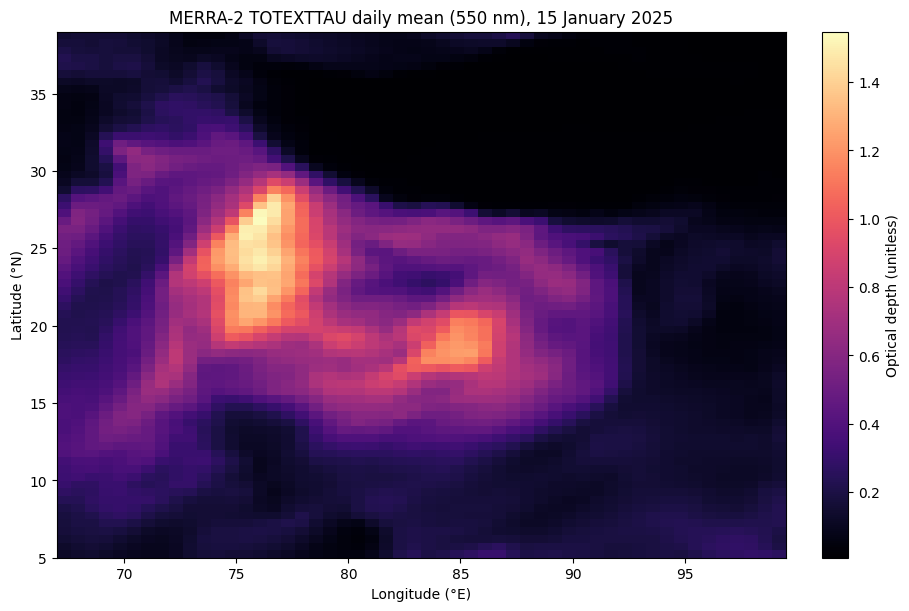

MERRA grid coordinate direction: latitude ascending
Valid MERRA range: 0.0079–1.5478


In [5]:
mx, my = merra_group["x"][:], merra_group["y"][:]
merra_plot = np.where(merra == -9999, np.nan, merra)
merra_extent = [mx[0] - .3125, mx[-1] + .3125, my[0] - .25, my[-1] + .25]
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
im = ax.imshow(merra_plot, extent=merra_extent, origin="lower", cmap="magma", aspect="auto")
ax.set(title="MERRA-2 TOTEXTTAU daily mean (550 nm), 15 January 2025",
       xlabel="Longitude (°E)", ylabel="Latitude (°N)")
fig.colorbar(im, ax=ax, label="Optical depth (unitless)")
plt.show()
print("MERRA grid coordinate direction:", "latitude ascending" if my[-1] > my[0] else "latitude descending")
print(f"Valid MERRA range: {np.nanmin(merra_plot):.4f}–{np.nanmax(merra_plot):.4f}")

In [6]:
def tree_bytes(path):
    return sum(p.stat().st_size for p in path.rglob("*") if p.is_file())

store_names = ["aod.zarr", "era5.zarr", "merra2.zarr", "static.zarr"]
storage = pd.DataFrame([
    {"Store": name, "Bytes": tree_bytes(DATA / name), "MiB": tree_bytes(DATA / name) / 1024**2}
    for name in store_names if (DATA / name).exists()
])
display(storage.style.format({"Bytes": "{:,.0f}", "MiB": "{:.2f}"}))
print(f"Processed tree total: {tree_bytes(DATA):,} bytes ({tree_bytes(DATA)/1024**2:.2f} MiB)")
print(f"Temporary transfer files left: {sum(1 for p in (ROOT/'data/raw/transfer').glob('*') if p.is_file()) if (ROOT/'data/raw/transfer').exists() else 0}")

eravalid = era != -9999
validation = pd.DataFrame([
    {"Check": "AOD complete spatial chunks", "Result": f"{int(aod_group['complete'][DAY_INDEX].sum())}/11", "Pass": int(aod_group['complete'][DAY_INDEX].sum()) == 11},
    {"Check": "AOD values within configured physical range", "Result": f"{np.nanmin(aod):.3f} to {np.nanmax(aod):.3f}", "Pass": bool(np.nanmin(aod) >= 0 and np.nanmax(aod) <= 3)},
    {"Check": "ERA5 date complete", "Result": bool(era_group['complete'][DAY_INDEX]), "Pass": bool(era_group['complete'][DAY_INDEX])},
    {"Check": "MERRA-2 date complete", "Result": bool(merra_group['complete'][DAY_INDEX]), "Pass": bool(merra_group['complete'][DAY_INDEX])},
    {"Check": "MERRA latitude coordinates match stored row order", "Result": "ascending", "Pass": bool(np.all(np.diff(my) > 0))},
    {"Check": "Elevation present", "Result": "Not downloaded; DEM export still being corrected", "Pass": False},
])
display(validation)
print("All core AOD and daily weather products completed for 2025-01-15.")

,Store,Bytes,MiB
0,aod.zarr,"2,252,519",2.15
1,era5.zarr,"1,113,568",1.06
2,merra2.zarr,"20,725",0.02
3,static.zarr,"33,744",0.03


Processed tree total: 15,520,303 bytes (14.80 MiB)
Temporary transfer files left: 0


,Check,Result,Pass
0,AOD complete spatial chunks,11/11,True
1,AOD values within configured physical range,0.000 to 2.999,True
2,ERA5 date complete,True,True
3,MERRA-2 date complete,True,True
4,MERRA latitude coordinates match stored row order,ascending,True
5,Elevation present,Not downloaded; DEM export still being corrected,False


All core AOD and daily weather products completed for 2025-01-15.
